PRVI ZADATAK


### 1

Polazi se od kontinualne dvodimenzionalne Gausove funkcije koja se, zbog primene
diskretne Furijeove transformacije, uzorkuje i ograničava na konačan broj tačaka.
Na taj način se dobija diskretna Gausova funkcija definisana na slici konacnih
dimenzija.
Posmatra se slika dimenzija $N_H \times N_W$. Dvodimenzionalna diskretna Gausova
funkcija sa različitim standardnim devijacijama po redovima i kolonama data je sa

$$
g(m,n) =
\exp\left(
-\frac{\left(m - \frac{N_H}{2}\right)^2}{2\sigma_{rS}^2}
-\frac{\left(n - \frac{N_W}{2}\right)^2}{2\sigma_{cS}^2}
\right),
$$

gde su:
- $m = 0,1,\ldots,N_H-1$ indeksi redova,
- $n = 0,1,\ldots,N_W-1$ indeksi kolona,
- $\sigma_{rS}$ i $\sigma_{cS}$ standardne devijacije u prostornom domenu.

Dvodimenzionalna diskretna Furijeova transformacija funkcije $g(m,n)$ definisana je
sledecim izrazom:

$$
G(k,l) =
\sum_{m=0}^{N_H-1}
\sum_{n=0}^{N_W-1}
g(m,n)\,
e^{-j2\pi\left(
\frac{k m}{N_H} + \frac{l n}{N_W}
\right)},
$$

gde su $k = 0,1,\ldots,N_H-1$ i $l = 0,1,\ldots,N_W-1$ frekvencijski indeksi.

Dvodimenzionalna Gausova funkcija je separabilna i moze se zapisati kao proizvod
dve jednodimenzionalne Gausove funkcije:

$$
g(m,n) = g_r(m)\, g_c(n),
$$

gde je

$$
g_r(m) = \exp\left(-\frac{\left(m - \frac{N_H}{2}\right)^2}{2\sigma_{rS}^2}\right),
\quad
g_c(n) = \exp\left(-\frac{\left(n - \frac{N_W}{2}\right)^2}{2\sigma_{cS}^2}\right).
$$

Zbog separabilnosti, i dvodimenzionalna DFT se moze posmatrati kao proizvod dve jednodimenzionalne DFT.

Poznato je da Furijeova transformacija Gausove funkcije daje opet Gausovu funkciju.
Zbog toga se moze zakljuciti da je i diskretna Furijeova transformacija dvodimenzionalne Gausove funkcije oblika:

$$
G(k,l) =
C \,
\exp\left(
-\frac{k^2}{2\sigma_{rF}^2}
-\frac{l^2}{2\sigma_{cF}^2}
\right),
$$

gde su $\sigma_{rF}$ i $\sigma_{cF}$ standardne devijacije u frekvencijskom domenu,
a $C$ konstanta proporcionalnosti.

Uporedjivanjem eksponencijalnih clanova dobija se veza izmedju standardnih devijacija u prostornom i frekvencijskom domenu:

$$
\sigma_{rF} = \frac{N_H}{2\pi\sigma_{rS}},
\qquad
\sigma_{cF} = \frac{N_W}{2\pi\sigma_{cS}}.
$$

Iz izraza se vidi da su standardne devijacije u frekvencijskom domenu obrnuto
proporcionalne standardnim devijacijama u prostornom domenu i proporcionalne
broju tačaka diskretizacije.

Diskretna Furijeova transformacija dvodimenzionalne Gausove funkcije daje opet
Gausovu funkciju u frekvencijskom domenu. Sirina spektra je obrnuto proporcionalna
sirini funkcije u prostornom domenu, sto potvrdjuje poznatu osobinu Gausove funkcije.




### 2

In [1]:
import skimage as ski

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import scipy.ndimage as ndi
import scipy.io
from skimage import io, img_as_float


In [2]:
data_dir = ('sekvence//')

In [3]:
def lpfilter(filt_type, Ny, Nx, sigma, n=1):
    
    if (Ny%2 == 0):
        y = np.arange(0,Ny) - Ny/2 + 0.5
    else:
        y = np.arange(0,Ny) - (Ny-1)/2
    
    if (Nx%2 == 0):
        x = np.arange(0,Nx) - Nx/2 + 0.5
    else:
        x = np.arange(0,Nx) - (Nx-1)/2

    
    X, Y = np.meshgrid(x, y)
    
    D = np.sqrt(np.square(X) + np.square(Y))
    
    if filt_type == 'gaussian':
        filter_mask = np.exp(-np.square(D)/(2*np.square(sigma)))
    elif filt_type == 'btw':
        filter_mask = 1/(1+(D/sigma)**(2*n))
    elif filt_type == 'ideal':
        filter_mask = np.ones([Ny, Nx])
        filter_mask[D>sigma] = 0
    else:
        print('Greška! Nije podržan tip filtra: ', filt_type)
        return
    
    return filter_mask

Izvršeno je filtriranje slike u frekvencijskom i prostornom domenu primenom Gausovog niskopropusnog filtra. Slika je najpre transformisana u frekvencijski domen pomoću dvodimenzionalne diskretne Furijeove transformacije i filtrirana za vise vrednosti standardne devijacije u frekvencijskom domenu. Na osnovu teorijske veze izmedju parametara Gausove funkcije u prostornom i frekvencijskom domenu odredjene su ekvivalentne vrednosti standardne devijacije u prostornom domenu, nakon cega je izvrseno prostorno filtriranje. Dobijeni rezultati su uporedjeni vizuelno i numericki pomocu najvece apsolutne greske, cime je potvrdjena ekvivalentnost oba pristupa. Uocavamo da najveca apsolutna greska opada sa porastom standardne devijacije, sto je posledica smanjenog uticaja diskretizacije i ivicnih efekata kod sirih Gausovih filtara.

0.07725392072702364 0.01608063177586483 0.003181951747296078


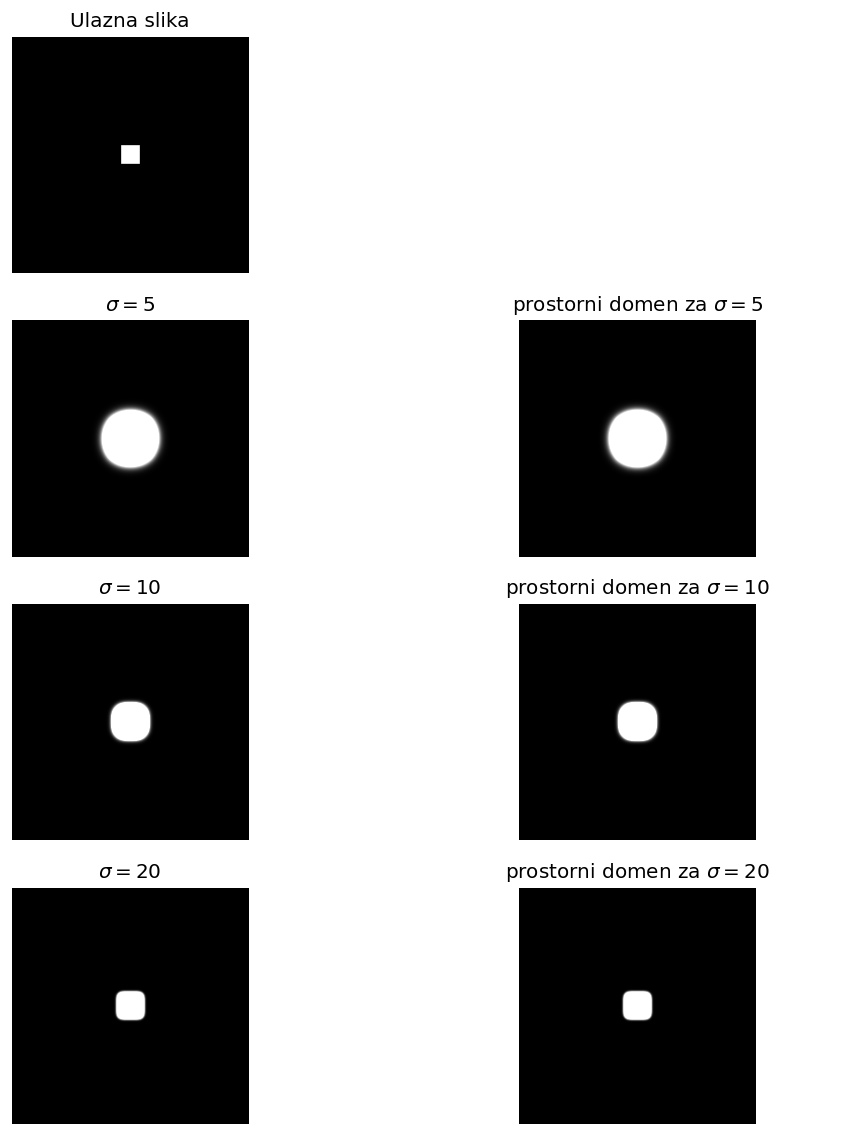

In [4]:
img = ski.util.img_as_float(ski.io.imread(data_dir + 'square_256x256.tif'))

[Ny, Nx] = np.shape(img)

img_fft = np.fft.fftshift(np.fft.fft2(img))
filt_freq1 = lpfilter('gaussian', Ny, Nx, sigma=5)
filt_freq2 = lpfilter('gaussian', Ny, Nx, sigma=10)
filt_freq3 = lpfilter('gaussian', Ny, Nx, sigma=20)

img_fft_filt1 = img_fft*filt_freq1
img_fft_filt2 = img_fft*filt_freq2
img_fft_filt3 = img_fft*filt_freq3

img_filt1 = np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt1)))
img_filt1 = np.clip(img_filt1, 0, 1)

img_filt2 = np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt2)))
img_filt2 = np.clip(img_filt2, 0, 1)

img_filt3 = np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt3)))
img_filt3 = np.clip(img_filt3, 0, 1)

sigmas1 = Nx/(2*np.pi*5)
sigmas2 = Nx/(2*np.pi*10)
sigmas3 = Nx/(2*np.pi*20)


img_filt1_spatial = gaussian_filter(img, sigmas1)
img_filt2_spatial = gaussian_filter(img, sigmas2)
img_filt3_spatial = gaussian_filter(img, sigmas3)

img_filt1_spatial = np.clip(img_filt1_spatial, 0, 1)
img_filt2_spatial = np.clip(img_filt2_spatial, 0, 1)
img_filt3_spatial = np.clip(img_filt3_spatial, 0, 1)

error1 = np.max(np.abs(img_filt1 - img_filt1_spatial))
error2 = np.max(np.abs(img_filt2 - img_filt2_spatial))
error3 = np.max(np.abs(img_filt3 - img_filt3_spatial))


print(error1, error2, error3)

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(10,12), dpi=120)
ax = axes.ravel()

ax[0].imshow(img, cmap='gray'); ax[0].set_axis_off(); ax[0].set_title('Ulazna slika')
ax[1].set_axis_off();

ax[2].imshow(img_filt1, cmap='gray'); ax[2].set_axis_off(); ax[2].set_title('$\sigma = 5$')
ax[3].imshow(img_filt1_spatial, cmap='gray'); ax[3].set_axis_off(); ax[3].set_title('prostorni domen za $\sigma = 5$')

ax[4].imshow(img_filt2, cmap='gray'); ax[4].set_axis_off(); ax[4].set_title('$\sigma = 10$')
ax[5].imshow(img_filt2_spatial, cmap='gray'); ax[5].set_axis_off(); ax[5].set_title('prostorni domen za $\sigma = 10$')

ax[6].imshow(img_filt3, cmap='gray'); ax[6].set_axis_off(); ax[6].set_title('$\sigma = 20$')
ax[7].imshow(img_filt3_spatial, cmap='gray'); ax[7].set_axis_off(); ax[7].set_title('prostorni domen za $\sigma = 20$');

Zbog razlicitih dimenzija slike po horizontalnom i vertikalnom pravcu, primena istog Gausovog filtra u frekvencijskom domenu dovodi do nejednakog stepena zamucenja po redovima i kolonama. Uocava se da je zamucenje izrazenije u pravcu sa vecim brojem diskretnih tacaka. Sa porastom standardne devijacije filtra dolazi do jacanja efekta niskopropusnog filtriranja i smanjenja visih frekvencija. Da bi se postigao jednak stepen zamucenja po redovima i kolonama, standardne devijacije Gausovog filtra u frekvencijskom domenu moraju biti razlicite po ta dva pravca i prilagodjene dimenzijama slike.

256 1024


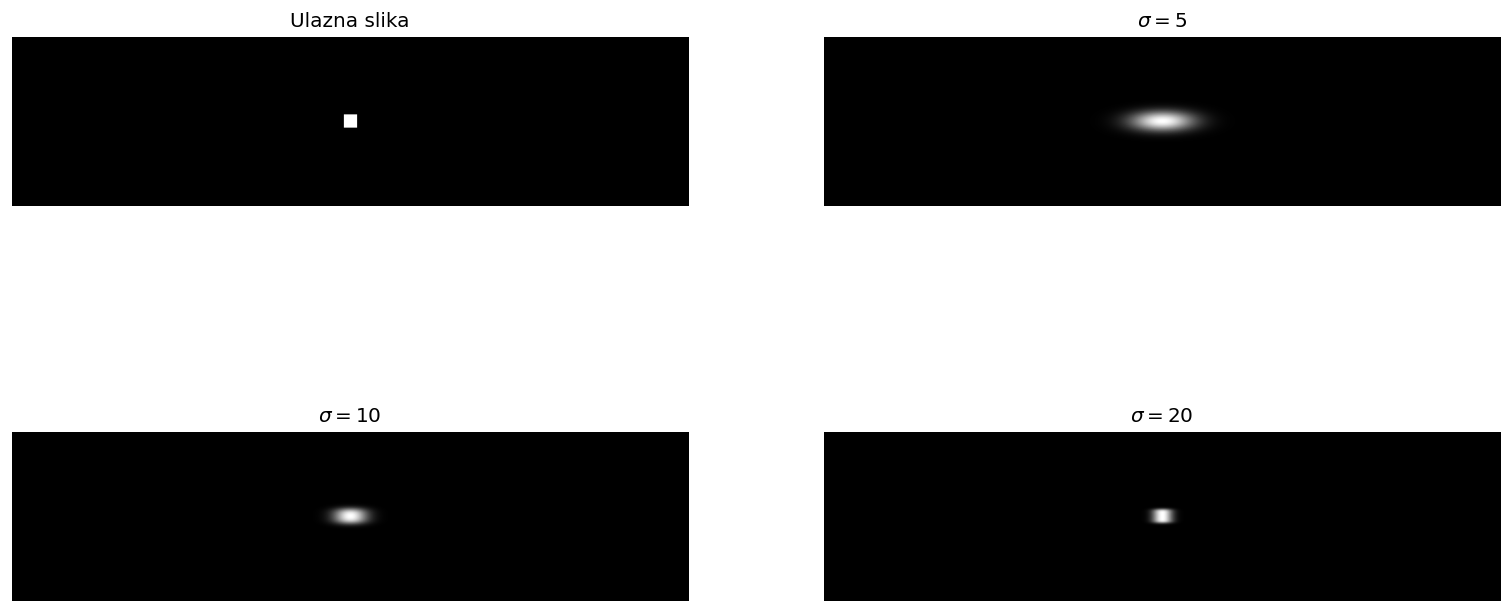

In [5]:
img2 = ski.util.img_as_float(ski.io.imread(data_dir + 'square_256x1024.tif'))

[Ny, Nx] = np.shape(img2)

print(Ny, Nx)

img_fft_1 = np.fft.fftshift(np.fft.fft2(img2))
filt_freq_1 = lpfilter('gaussian', Ny, Nx, sigma=5)
filt_freq_2 = lpfilter('gaussian', Ny, Nx, sigma=10)
filt_freq_3 = lpfilter('gaussian', Ny, Nx, sigma=20)

img_fft_filt_1 = img_fft_1*filt_freq_1
img_fft_filt_2 = img_fft_1*filt_freq_2
img_fft_filt_3 = img_fft_1*filt_freq_3

img_filt_1= np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt_1)))
img_filt_1 = np.clip(img_filt_1, 0, 1)

img_filt_2= np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt_2)))
img_filt_2 = np.clip(img_filt_2, 0, 1)

img_filt_3= np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt_3)))
img_filt_3 = np.clip(img_filt_3, 0, 1)

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16,8), dpi=120)
ax = axes.ravel()

ax[0].imshow(img2, cmap='gray'); ax[0].set_axis_off(); ax[0].set_title('Ulazna slika')
ax[1].imshow(img_filt_1, cmap='gray'); ax[1].set_axis_off(); ax[1].set_title('$\sigma = 5$');
ax[2].imshow(img_filt_2, cmap='gray'); ax[2].set_axis_off(); ax[2].set_title('$\sigma = 10$');
ax[3].imshow(img_filt_3, cmap='gray'); ax[3].set_axis_off(); ax[3].set_title('$\sigma = 20$');

In [6]:
def lpfilter_anisotrop(filt_type, Ny, Nx, sigmaX, sigmaY, n=1):
    
    if (Ny%2 == 0):
        y = np.arange(0,Ny) - Ny/2 + 0.5
    else:
        y = np.arange(0,Ny) - (Ny-1)/2
    
    if (Nx%2 == 0):
        x = np.arange(0,Nx) - Nx/2 + 0.5
    else:
        x = np.arange(0,Nx) - (Nx-1)/2

    
    X, Y = np.meshgrid(x, y)
    
    D = np.sqrt(np.square(X/sigmaX) + np.square(Y/sigmaY))
    
    if filt_type == 'gaussian':
        filter_mask = np.exp(-((X**2/(2*(sigmaX)**2)) + (Y**2)/(2*(sigmaY)**2)))
    elif filt_type == 'btw':
        filter_mask = 1/(1+(D)**(2*n))
    elif filt_type == 'ideal':
        filter_mask = np.ones([Ny, Nx])
        filter_mask[D >= 1] = 0
    else:
        print('Greška! Nije podržan tip filtra: ', filt_type)
        return
    
    return filter_mask

0.07725392072702597 1.0 1.0


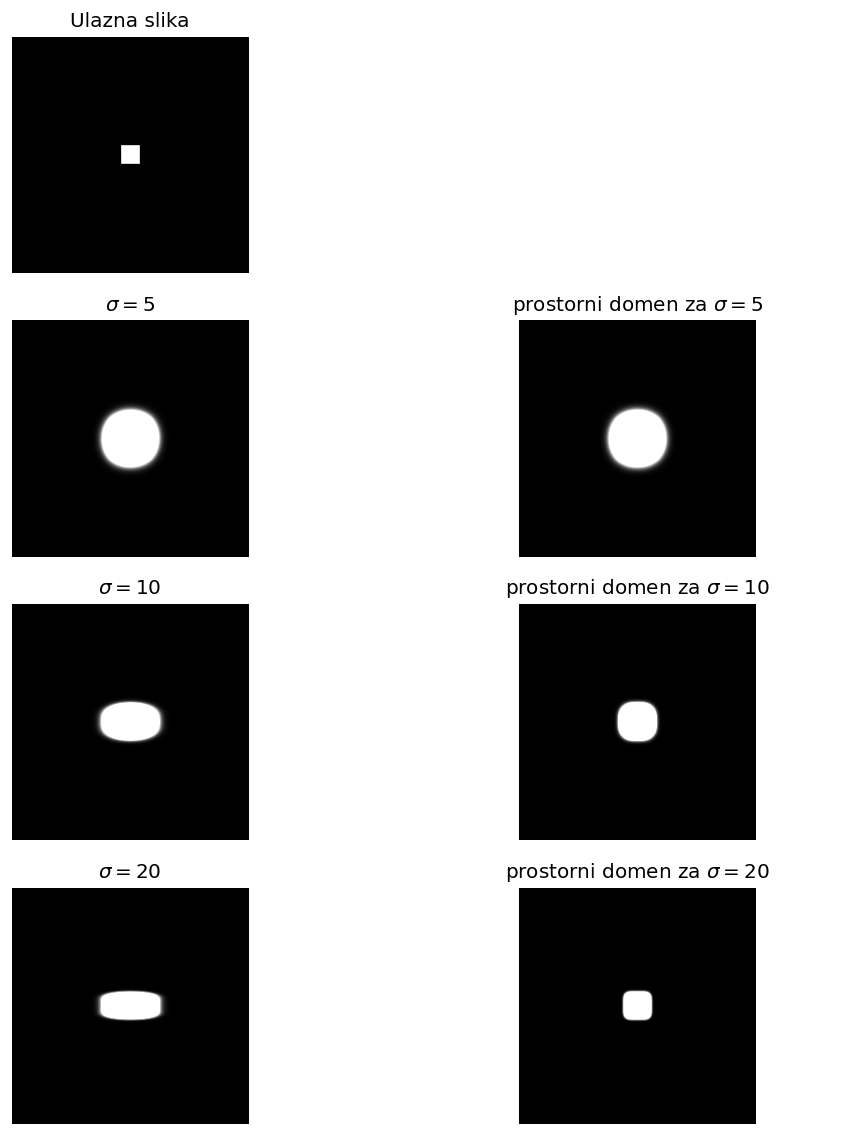

In [7]:
img = ski.util.img_as_float(ski.io.imread(data_dir + 'square_256x256.tif'))

[Ny, Nx] = np.shape(img)

img_fft = np.fft.fftshift(np.fft.fft2(img))
filt_freq2_1 = lpfilter_anisotrop('gaussian', Ny, Nx, sigmaX = 5, sigmaY = 5)
filt_freq2_2 = lpfilter_anisotrop('gaussian', Ny, Nx, sigmaX = 5, sigmaY = 10)
filt_freq2_3 = lpfilter_anisotrop('gaussian', Ny, Nx, sigmaX = 5, sigmaY = 20)

img_fft_filt2_1 = img_fft*filt_freq2_1
img_fft_filt2_2 = img_fft*filt_freq2_2
img_fft_filt2_3 = img_fft*filt_freq2_3

img_filt2_1 = np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt2_1)))
img_filt2_1 = np.clip(img_filt2_1, 0, 1)

img_filt2_2 = np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt2_2)))
img_filt2_2 = np.clip(img_filt2_2, 0, 1)

img_filt2_3 = np.real(np.fft.ifft2(np.fft.ifftshift(img_fft_filt2_3)))
img_filt2_3 = np.clip(img_filt2_3, 0, 1)

sigmas1y = Ny/(2*np.pi*5)
sigmas1x = Nx/(2*np.pi*5)

sigmas2y = Ny/(2*np.pi*10)
sigmas2x = Nx/(2*np.pi*10)

sigmas3y = Ny/(2*np.pi*20)
sigmas3x = Nx/(2*np.pi*20)


img_filt2_1_spatial = gaussian_filter(img, sigma=[sigmas1y, sigmas1x])
img_filt2_2_spatial = gaussian_filter(img, sigma=[sigmas2y, sigmas2x])
img_filt2_3_spatial = gaussian_filter(img, sigma=[sigmas3y, sigmas3x])

img_filt2_1_spatial = np.clip(img_filt2_1_spatial, 0, 1)
img_filt2_2_spatial = np.clip(img_filt2_2_spatial, 0, 1)
img_filt2_3_spatial = np.clip(img_filt2_3_spatial, 0, 1)

error2_1 = np.max(np.abs(img_filt2_1 - img_filt2_1_spatial))
error2_2 = np.max(np.abs(img_filt2_2 - img_filt2_2_spatial))
error2_3 = np.max(np.abs(img_filt2_3 - img_filt2_3_spatial))


print(error2_1, error2_2, error2_3)

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(10,12), dpi=120)
ax = axes.ravel()

ax[0].imshow(img, cmap='gray'); ax[0].set_axis_off(); ax[0].set_title('Ulazna slika')
ax[1].set_axis_off();

ax[2].imshow(img_filt2_1, cmap='gray'); ax[2].set_axis_off(); ax[2].set_title('$\sigma = 5$')
ax[3].imshow(img_filt2_1_spatial, cmap='gray'); ax[3].set_axis_off(); ax[3].set_title('prostorni domen za $\sigma = 5$')

ax[4].imshow(img_filt2_2, cmap='gray'); ax[4].set_axis_off(); ax[4].set_title('$\sigma = 10$')
ax[5].imshow(img_filt2_2_spatial, cmap='gray'); ax[5].set_axis_off(); ax[5].set_title('prostorni domen za $\sigma = 10$')

ax[6].imshow(img_filt2_3, cmap='gray'); ax[6].set_axis_off(); ax[6].set_title('$\sigma = 20$')
ax[7].imshow(img_filt2_3_spatial, cmap='gray'); ax[7].set_axis_off(); ax[7].set_title('prostorni domen za $\sigma = 20$');

### DRUGI ZADATAK

Pre Wienerove dekonvolucije slika je linearizovana pomocu inverzne gama korekcije, jer Wiener filtriranje najbolje funkcioniSe kada su intenziteti piksela linearno povezani sa osvetljenjem, sto omogucava precizniju inverziju zamucenja. Zatim je kernel i svaki kanal slike transformisan u frekvencijski domen, gde je primenjen Wiener filter, koji omogucava stabilnu inverziju efekta zamucenja uz kontrolu pojacanja suma pomocu parametra k. Nakon toga je primenjena inverzna Fourijeova transformacija da se rezultat vrati u prostorni domen, a zatim je ponovo izvrsena gama korekcija da bi se slika vratila u sRGB prostor za pravilno vizuelno prikazivanje. Na kraju su vrednosti piksela ogranicene na opseg od 0 do 1 kako bi se sprecili artefakti i obezbedila validnost slike.

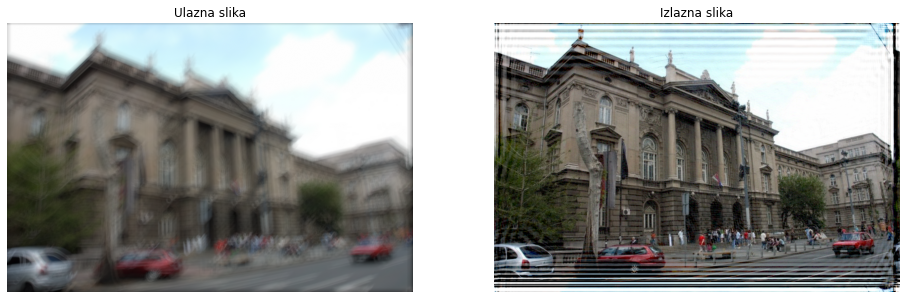

In [8]:
# Ucitavanje slike
img3 = img_as_float(io.imread(data_dir + 'etf_blur.png'))

Ny, Nx, Ni = img3.shape 

# Inverzna gama korekcija (linearizacija)
gamma = 2.2
img_lin = img3 ** gamma

# Ucitavanje i normalizacija kernela
DATA = np.loadtxt(data_dir + 'blur_kernel.txt')

# Fourijeova PSF(point spread function)
H_blur = np.fft.fftshift(np.fft.fft2(DATA, s=(Ny, Nx)))

# Wiener parametar
k = 1e-3   # mora biti VEĆI nego bez linearizacije

# Izlaz u linearnom domenu
img_est_lin = np.zeros_like(img_lin)

for i in range(Ni):
    img_fft = np.fft.fftshift(np.fft.fft2(img_lin[:,:,i]))
    
    W = (abs(H_blur)**2) / (abs(H_blur)**2 + k)
    img_fft_est = (img_fft / (H_blur + k)) * W
    
    img_est_lin[:,:,i] = np.real(
        np.fft.ifft2(np.fft.ifftshift(img_fft_est))
    )

# Clip u linearnom domenu
img_est_lin = np.clip(img_est_lin, 0, 1)

# Gama korekcija nazad (za prikaz)
img_est = img_est_lin ** (1/gamma)

# Prikaz
fig, axes = plt.subplots(1, 2, figsize=(16, 16))
axes[0].imshow(img3); axes[0].set_title('Ulazna slika'); axes[0].axis('off')
axes[1].imshow(img_est); axes[1].set_title('Izlazna slika'); axes[1].axis('off')
plt.show()


### TRECI ZADATAK


U kodu sam ucitao test sliku i dodao joj gausov sum poznate varijanse. Zatim sam primenom uniformnog box filtra izracunao lokalnu srednju vrednost slike i lokalnu srednju vrednost kvadrata intenziteta. Na osnovu ovih vrednosti dobio sam mapu lokalne varijanse, uz primenu korekcionog faktora.

Iz svih lokalnih varijansi formirao sam histogram i kao procenu varijanse suma uzeo vrednost koja odgovara maksimumu histograma. Dobijene rezultate sam vizuelno prikazao radi analize i verifikacije procene.

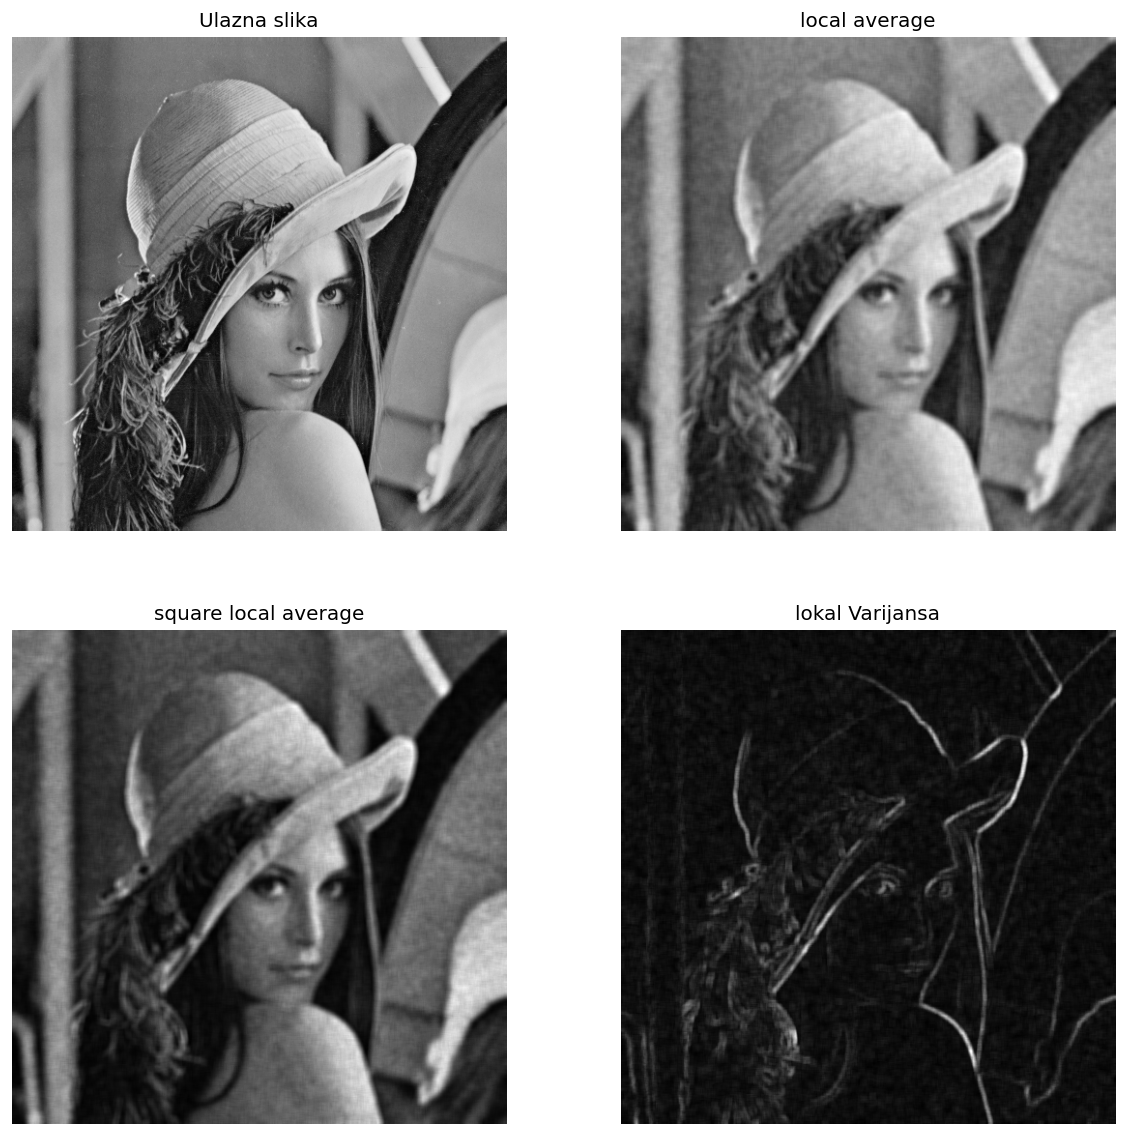

Odredjena varijansa gausovog suma je: 0.009850000000000001


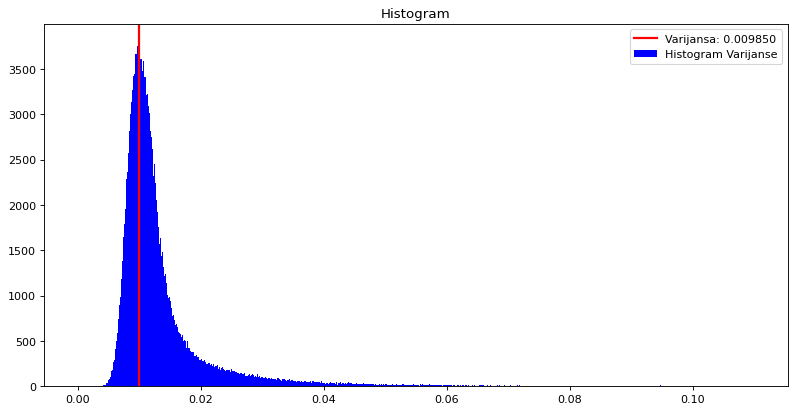

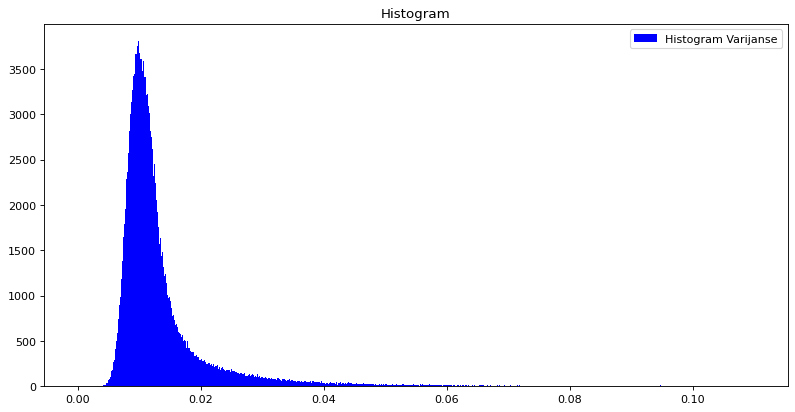

In [9]:
img = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
test_image = ski.util.random_noise(img, mode = 'gaussian', mean = 0, var = 0.01)

win = 7;
filter_average = np.ones([win, win])/(win**2)
local_average = ndi.correlate(test_image, filter_average)
square_local_average = ndi.correlate(test_image ** 2, filter_average)
local_variance = square_local_average - local_average**2
local_variance *= (win**2)/(win**2 - 1) 

fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (12,12), dpi = 120)
ax = axes.ravel()
ax[0].imshow(img, cmap = 'gray');
ax[0].set_axis_off()
ax[0].set_title('Ulazna slika')
ax[1].imshow(local_average, cmap = 'gray');
ax[1].set_axis_off()
ax[1].set_title('local average')
ax[2].imshow(square_local_average, cmap = 'gray');
ax[2].set_axis_off()
ax[2].set_title('square local average')
ax[3].imshow(local_variance, cmap = 'gray');
ax[3].set_axis_off()
ax[3].set_title('lokal Varijansa')
plt.show()


# Histogram
# odustao sam od dinamicke procene opsega histograma
histogram_variance, bin_edges = np.histogram(local_variance.flatten(), bins = 1100, range = (0, 0.11))
variance_index = np.argmax(histogram_variance)
variance = (bin_edges[variance_index] + bin_edges[variance_index + 1]) / 2.0  
print(f'Odredjena varijansa gausovog suma je: {variance}') 

plt.figure(figsize = (12, 6), dpi = 80)
plt.bar(bin_edges[0:-1], histogram_variance, width = np.diff(bin_edges), color = 'b', label = 'Histogram Varijanse')
plt.axvline(x = variance, color = 'red', linestyle = '-', linewidth = 2,
            label = f'Varijansa: {variance:.6f}')
plt.legend();
plt.title('Histogram')
plt.show()

plt.figure(figsize = (12, 6), dpi = 80)
plt.bar(bin_edges[0:-1], histogram_variance, width = np.diff(bin_edges), color = 'b', label = 'Histogram Varijanse')
plt.legend();
plt.title('Histogram')
plt.show()


In [10]:
def estimate_noise_var_simple(img, win = 0,  debug = False):
    win = win;    
    filter_average = np.ones([win, win])/(win**2)
    local_average = ndi.correlate(img, filter_average)
    square_local_average = ndi.correlate(img ** 2, filter_average)
    local_variance = square_local_average - local_average**2

    if debug:
        fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (12,12), dpi = 120)
        ax = axes.ravel()
        ax[0].imshow(img, cmap = 'gray');
        ax[0].set_axis_off()
        ax[0].set_title('Ulazna slika')
        ax[1].imshow(local_average, cmap = 'gray');
        ax[1].set_axis_off()
        ax[1].set_title('lokal averidz')
        ax[2].imshow(square_local_average, cmap = 'gray');
        ax[2].set_axis_off()
        ax[2].set_title('skver lokal averidz')
        ax[3].imshow(local_variance, cmap = 'gray');
        ax[3].set_axis_off()
        ax[3].set_title('lokalVarijans')
        plt.show()
    
    

    histogram_variance, bin_edges = np.histogram(local_variance.flatten(), bins = 1000, range = (0, 0.12))
    variance_index = np.argmax(histogram_variance)
    variance = (bin_edges[variance_index] + bin_edges[variance_index + 1]) / 2.0  
    print(f'Odredjena varijansa gausovog suma je: {variance}') 

    if debug:
        plt.figure(figsize = (12, 6), dpi = 80)
        plt.bar(bin_edges[0:-1], histogram_variance, width = np.diff(bin_edges), color = 'b', label = 'Histogram Varijanse')
        plt.axvline(x = variance, color = 'red', linestyle = '-', linewidth = 2,
                    label = f'Variance: {variance:.6f}')
        plt.legend();
        plt.title('Histogram')
        plt.show()
        
        plt.figure(figsize = (12, 6), dpi = 80)
        plt.bar(bin_edges[0:-1], histogram_variance, width = np.diff(bin_edges), color = 'b', label = 'Histogram Varijanse')
        plt.legend();
        plt.title('Histogram')
        plt.show()
    
    max_hist_value = histogram_variance[variance_index]  # max hist value ce biti potreban za tacke 2 i 3 treceg zadatka
    
    return variance, max_hist_value


Sada mozemo da napravimo trazenu funkciju koristeci simple verziju. U odnosu na potpis funkcije trazen u tacki 3.1 ova je "nadogradjena", jer osim sto vraca varijansu, vraca i velicinu prozora na kojoj je ta varijansa pronadjena, sto ce nam biti potrebno u tackama 3.2 i 3.3

In [11]:
def estimate_noise_var(img, win = 0, tol = 0.001):
    if win:
        var, _ = estimate_noise_var_simple(img = img, win = win)
        return var, win
    else:
        last_variance = None
        window = 3
        while window <= 51:
            current_variance, max_hist_value = estimate_noise_var_simple(img, win = window)
            if last_variance is not None:
                difference = current_variance - last_variance
                if abs(difference) < tol:
                    return current_variance, window
            last_variance = current_variance
            window += 2;
        return current_variance, window
            

Testiranje: 
Ono o cemu treba voditi racuna pri gledanju ovih rezultata, je to kako se slika zasumljava, odnosno kako se sum unosi u sliku. Sledeca dva bloka koda se osvrcu na to. U zavisnosti od toga kako je sum unesen dobijamo razlicite vrednosti varijanse, za istu unetu varijansu. Ovo je sasvim logicno ako uzmemo u obzir opseg float vrednosti koje koduju boju piksela i kako se nad njima zasumljavanje u razlicitim bibliotekama.

In [12]:
def numpy_gaussian_noise(img, mean=0, var=0.045, clip=True):
    noise = np.random.normal(loc=mean, scale=np.sqrt(var), size=img.shape)
    noisy_img = img + noise
    if clip:
        noisy_img = np.clip(noisy_img, 0, 1)
    
    return noisy_img

Generisao sam vise verzija zasumljene slike koristeci razlicite nacine dodavanja gausovog suma, ukljucujuci funkciju random_noise iz biblioteke skimage.

Za svaku dobijenu zasumljenu sliku primenio sam funkciju estimate_noise_var, pri cemu sam koristio zadatu toleranciju kako bih automatski odredio optimalnu velicinu lokalnog susedstva. Iz funkcije sam dobio procenjenu varijansu suma i odgovarajucu velicinu prozora, a rezultate sam ispisao i vizuelno uporedio prikazom zasumljenih slika.

Odredjena varijansa gausovog suma je: 0.049859999999999995
Odredjena varijansa gausovog suma je: 0.07205999999999999
Odredjena varijansa gausovog suma je: 0.07158
(SKI.RANDOM.NOISE)Finalna Varijansa je 0.07158, dobijena za prozor velicine: 7
Odredjena varijansa gausovog suma je: 0.07685999999999998
Odredjena varijansa gausovog suma je: 0.08465999999999999
Odredjena varijansa gausovog suma je: 0.09173999999999999
Odredjena varijansa gausovog suma je: 0.09677999999999999
Odredjena varijansa gausovog suma je: 0.10325999999999999
Odredjena varijansa gausovog suma je: 0.10074
Odredjena varijansa gausovog suma je: 0.10253999999999999
Odredjena varijansa gausovog suma je: 0.10277999999999998
(ADDITIVE)Finalna Varijansa je 0.10277999999999998, dobijena za prozor velicine: 17
Odredjena varijansa gausovog suma je: 0.057539999999999994
Odredjena varijansa gausovog suma je: 0.06366
Odredjena varijansa gausovog suma je: 0.07602
Odredjena varijansa gausovog suma je: 0.07782
Odredjena varijansa gauso

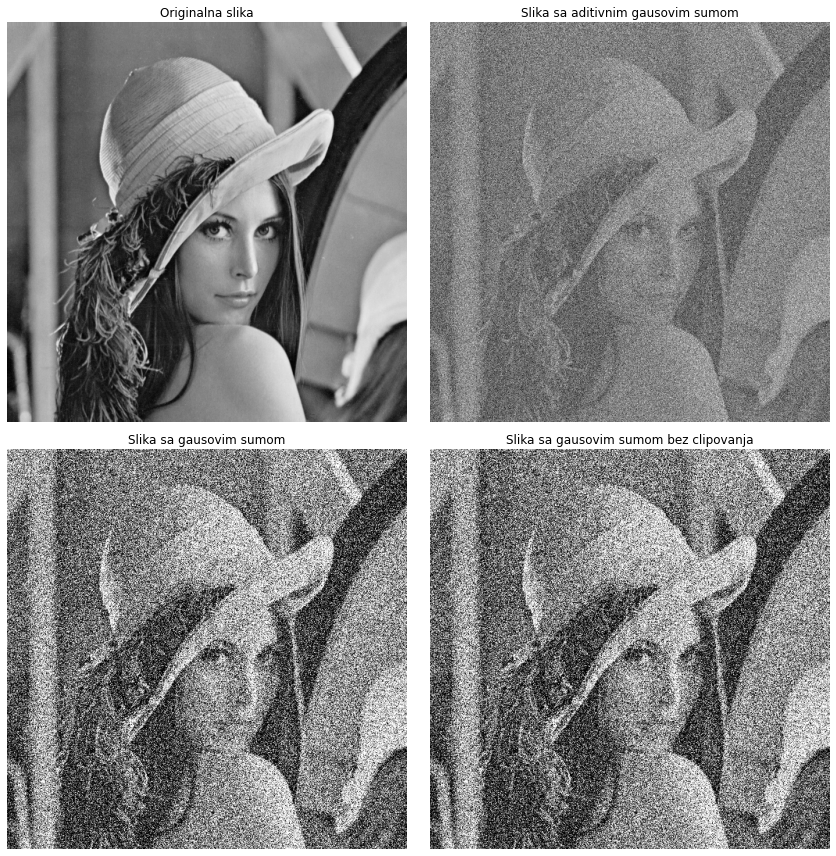

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.ravel()

var_test = 0.1
img = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Originalna slika')
axes[0].set_axis_off()
img_noise = ski.util.random_noise(img, mode = 'gaussian', mean = 0, var = var_test)
variance, window = estimate_noise_var(img = img_noise, tol = 0.0005)
print(f'(SKI.RANDOM.NOISE)Finalna Varijansa je {variance}, dobijena za prozor velicine: {window}')

img_noise = img + np.random.normal(0, np.sqrt(0.1), img.shape)
axes[1].imshow(img_noise, cmap='gray')
axes[1].set_title('Slika sa aditivnim gausovim sumom')
axes[1].set_axis_off()
variance, window = estimate_noise_var(img = img_noise, tol = 0.0005)
print(f'(ADDITIVE)Finalna Varijansa je {variance}, dobijena za prozor velicine: {window}')

img_noise = numpy_gaussian_noise(img, mean=0, var=var_test)
axes[2].imshow(img_noise, cmap='gray')
axes[2].set_title('Slika sa gausovim sumom')
axes[2].set_axis_off()
variance, window = estimate_noise_var(img = img_noise, tol = 0.0005)
print(f'(NP2)Finalna Varijansa je {variance}, dobijena za prozor velicine: {window}')

img_noise_no_clip = numpy_gaussian_noise(img, mean=0, var=var_test, clip=False)
variance, window = estimate_noise_var(img = img_noise, tol = 0.0005)
print(f'(NP3)Finalna Varijansa je {variance}, dobijena za prozor velicine: {window}')
axes[3].imshow(img_noise, cmap='gray')
axes[3].set_title('Slika sa gausovim sumom bez clipovanja')
axes[3].set_axis_off()

plt.tight_layout()
plt.show()

In [14]:
#Provera "batch" trazenja varijanse
img_noise = ski.util.random_noise(img, mode = 'gaussian', mean = 0, var = 0.01)

for window in range(3, 51, 4):
    variance, window = estimate_noise_var(img = img_noise, win = window, tol = 0.0003)
    print(f'Varijansa je {variance}, dobijena za prozor velicine: {window}')



Odredjena varijansa gausovog suma je: 0.006659999999999999
Varijansa je 0.006659999999999999, dobijena za prozor velicine: 3
Odredjena varijansa gausovog suma je: 0.010019999999999998
Varijansa je 0.010019999999999998, dobijena za prozor velicine: 7
Odredjena varijansa gausovog suma je: 0.010259999999999998
Varijansa je 0.010259999999999998, dobijena za prozor velicine: 11
Odredjena varijansa gausovog suma je: 0.010259999999999998
Varijansa je 0.010259999999999998, dobijena za prozor velicine: 15
Odredjena varijansa gausovog suma je: 0.01014
Varijansa je 0.01014, dobijena za prozor velicine: 19
Odredjena varijansa gausovog suma je: 0.01038
Varijansa je 0.01038, dobijena za prozor velicine: 23
Odredjena varijansa gausovog suma je: 0.010499999999999999
Varijansa je 0.010499999999999999, dobijena za prozor velicine: 27
Odredjena varijansa gausovog suma je: 0.01038
Varijansa je 0.01038, dobijena za prozor velicine: 31
Odredjena varijansa gausovog suma je: 0.010259999999999998
Varijansa je 

Odredjena varijansa gausovog suma je: 0.006539999999999999
Odredjena varijansa gausovog suma je: 0.0093
Odredjena varijansa gausovog suma je: 0.00978
Odredjena varijansa gausovog suma je: 0.009899999999999999
Finalna Varijansa je 0.009899999999999999, dobijena za prozor velicine: 9

 Testiranje sa specificnim velicinama prozora
Odredjena varijansa gausovog suma je: 0.006539999999999999
Varijansa je 0.006540, dobijena za prozor velicine: 3
Odredjena varijansa gausovog suma je: 0.00978
Varijansa je 0.009780, dobijena za prozor velicine: 7
Odredjena varijansa gausovog suma je: 0.01014
Varijansa je 0.010140, dobijena za prozor velicine: 11
Odredjena varijansa gausovog suma je: 0.01014
Varijansa je 0.010140, dobijena za prozor velicine: 15
Odredjena varijansa gausovog suma je: 0.010259999999999998
Varijansa je 0.010260, dobijena za prozor velicine: 19
Odredjena varijansa gausovog suma je: 0.01014
Varijansa je 0.010140, dobijena za prozor velicine: 23
Odredjena varijansa gausovog suma je: 0.

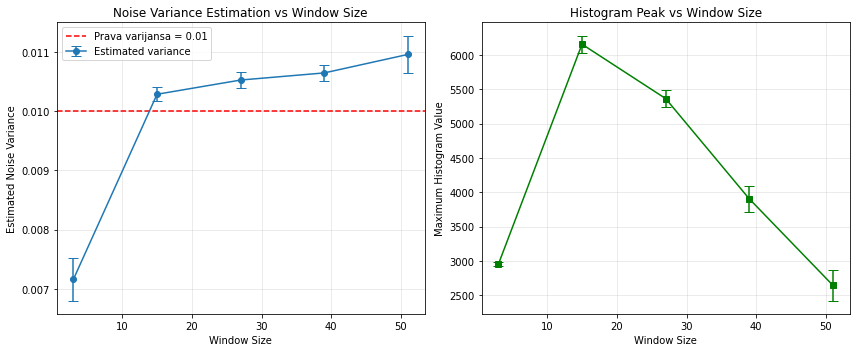


 Summary Statistics
True variance: 0.01
Number of cycles: 5
Measurements per window: 3
Total measurements per window: 15

Window Size | Mean Variance | Std Dev | Mean Hist Peak | Std Dev Hist Peak
----------------------------------------------------------------------
     3      | 0.007164       | 0.000359 | 2951           | 28
    15      | 0.010284       | 0.000118 | 6155           | 125
    27      | 0.010524       | 0.000140 | 5364           | 120
    39      | 0.010644       | 0.000140 | 3904           | 187
    51      | 0.010956       | 0.000317 | 2644           | 222


In [15]:
def run_experiments():
    img = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
    true_variance = 0.01
    num_cycles = 5  
    num_measurements_per_window = 3  
    
    window_sizes = np.linspace(3, 51, num_cycles, dtype=int)
    window_sizes = [w if w % 2 == 1 else w + 1 for w in window_sizes]
    
    all_estimated_variances = np.zeros((len(window_sizes), num_cycles * num_measurements_per_window))
    all_max_hist_values = np.zeros((len(window_sizes), num_cycles * num_measurements_per_window))
    
    for cycle in range(num_cycles):
        img_noise = ski.util.random_noise(img, mode='gaussian', mean=0, var=true_variance)
        
        for i, win in enumerate(window_sizes):
            for measurement in range(num_measurements_per_window):
                idx = cycle * num_measurements_per_window + measurement
 
                estimated_variance, max_hist_value = estimate_noise_var_simple(img_noise, win)
                all_estimated_variances[i, idx] = estimated_variance
                all_max_hist_values[i, idx] = max_hist_value

    print("loop finished")

    
    mean_variances = np.mean(all_estimated_variances, axis=1)
    std_variances = np.std(all_estimated_variances, axis=1)
    mean_max_hist = np.mean(all_max_hist_values, axis=1)
    std_max_hist = np.std(all_max_hist_values, axis=1)
    
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.errorbar(window_sizes, mean_variances, yerr=std_variances, fmt='o-', capsize=5, label='Estimated variance')
    plt.axhline(y=true_variance, color='r', linestyle='--', label=f'Prava varijansa = {true_variance}')
    plt.xlabel('Window Size')
    plt.ylabel('Estimated Noise Variance')
    plt.title('Noise Variance Estimation vs Window Size')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.errorbar(window_sizes, mean_max_hist, yerr=std_max_hist, fmt='s-', capsize=5, color='green')
    plt.xlabel('Window Size')
    plt.ylabel('Maximum Histogram Value')
    plt.title('Histogram Peak vs Window Size')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print("\n Summary Statistics")
    print(f"True variance: {true_variance}")
    print(f"Number of cycles: {num_cycles}")
    print(f"Measurements per window: {num_measurements_per_window}")
    print(f"Total measurements per window: {num_cycles * num_measurements_per_window}")
    print("\nWindow Size | Mean Variance | Std Dev | Mean Hist Peak | Std Dev Hist Peak")
    print("-" * 70)
    for i, win in enumerate(window_sizes):
        print(f"{win:^11} | {mean_variances[i]:.6f}       | {std_variances[i]:.6f} | "
              f"{mean_max_hist[i]:.0f}           | {std_max_hist[i]:.0f}")
    
    return window_sizes, mean_variances, std_variances, mean_max_hist, std_max_hist


img = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
img_noise = ski.util.random_noise(img, mode='gaussian', mean=0, var=0.01)
variance, window = estimate_noise_var(img=img_noise, tol=0.0003)
print(f'Finalna Varijansa je {variance}, dobijena za prozor velicine: {window}')

print("\n Testiranje sa specificnim velicinama prozora")
for window in range(3, 51, 4):
    variance, _ = estimate_noise_var(img=img_noise, win=window, tol=0.0003)
    print(f'Varijansa je {variance:.6f}, dobijena za prozor velicine: {window}')

print("\n Ceo eksperiment")
results = run_experiments()

### CETVRTI ZADATAK

U ovoj funkciji sam implementirao self guided filter tako sto sam najpre sliku prebacio u tip podataka sa vecom preciznoscu radi stabilnog racunanja. Zatim sam formirao kvadratni lokalni prozor zadate velicine i pomocu korelacije izracunao zbir intenziteta i zbir kvadrata intenziteta u lokalnom susedstvu svakog piksela.

Na osnovu ovih vrednosti izracunao sam lokalnu srednju vrednost i lokalnu varijansu slike. Iz lokalne varijanse sam dobio koeficijent (a) koji odredjuje jacinu filtriranja u zavisnosti od strukture slike, dok sam koeficijent (b) izracunao tako da se sacuva lokalna srednja vrednost. Na kraju sam izlaznu sliku dobio primenom lokalnog linearnog modela nad originalnom slikom.

In [16]:
def dos_self_guided_filter(img, R, epsilon):
    I = img.astype(np.float64)
    q = np.zeros_like(I)

    filter_average = np.ones([2*R + 1, 2*R + 1])
    suma = ndi.correlate(I, filter_average)
    suma2 = ndi.correlate(I**2, filter_average)
    N = filter_average.size
    mean_I = suma/N
    var_I = suma2/N - mean_I**2
    a = var_I/(var_I + epsilon)
    b = mean_I - a * mean_I
    q = a * I + b
    return q

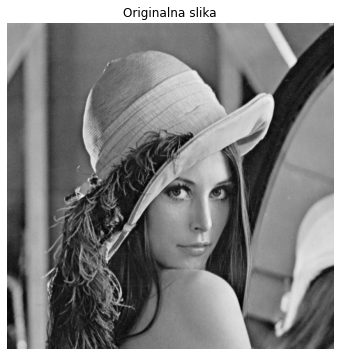

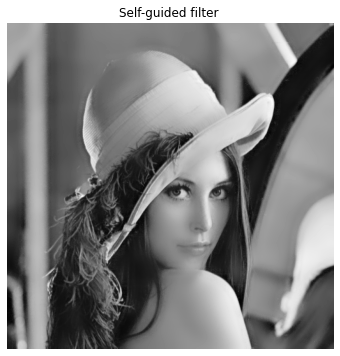

In [17]:
img6 = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
plt.figure(figsize=(6,6))
plt.imshow(img6, cmap='gray')   
plt.title('Originalna slika')
plt.axis('off')
plt.show()


img6 = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
q = dos_self_guided_filter(img6, 10, 1e-2)
plt.figure(figsize=(6,6))
plt.imshow(q, cmap='gray')   
plt.title('Self-guided filter ')
plt.axis('off')
plt.show()


U ovoj funkciji sam implementirao brzu varijantu self guided filtra tako sto sam najpre izvrsio decimaciju ulazne slike zadatim faktorom S kako bih smanjio broj piksela nad kojima se racunaju lokalne statistike. Velicinu lokalnog prozora sam prilagodio decimiranom domenu kako bi se sacuvala priblizna prostorna podrska filtra.

Na decimiranoj slici sam izracunao lokalnu srednju vrednost i lokalnu varijansu primenom box filtra, a zatim odredio koeficijente a i b koji opisuju lokalni linearni model. Dobijene koeficijente sam dodatno izgladio i zatim interpolirao nazad na originalnu rezoluciju slike pomocu bilinearne interpolacije.

Na kraju sam izlaznu sliku dobio primenom interpoliranih koeficijenata na originalnu sliku, cime je postignuto znacajno ubrzanje u odnosu na punu realizaciju uz minimalno odstupanje u kvalitetu rezultata.

In [18]:
def dos_fast_self_guided_filter(img, R, epsilon, S):
    I = img.astype(np.float64)
    H, W = I.shape
    I_downscale = I[::S, ::S]
    q = np.zeros_like(I)
    q_downscale = np.zeros_like(I_downscale)
    R_scaled = max(R//S, 1)

    filter_average = np.ones([2*R_scaled + 1, 2*R_scaled + 1])
    suma = ndi.correlate(I_downscale, filter_average)
    suma2 = ndi.correlate(I_downscale**2, filter_average)
    N = filter_average.size
    mean_I = suma/N
    var_I = suma2/N - mean_I**2
    a = var_I/(var_I + epsilon)
    b = mean_I - a * mean_I

    a_smooth = ndi.correlate(a, filter_average, mode='reflect')
    b_smooth = ndi.correlate(b, filter_average, mode='reflect')
    
    # Step 4: Upscale coefficients
    a_full = ndi.zoom(a_smooth, (S, S), order=1)[:H, :W]
    b_full = ndi.zoom(b_smooth, (S, S), order=1)[:H, :W]

    # a_full = np.repeat(np.repeat(a, S, axis=0), S, axis=1)[:H, :W]
    # b_full = np.repeat(np.repeat(b, S, axis=0), S, axis=1)[:H, :W]

    q = a_full * I + b_full

    
    return q    

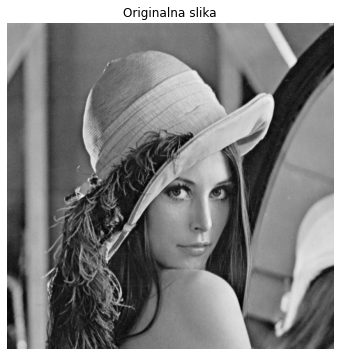

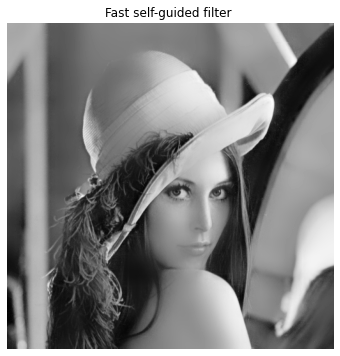

In [19]:
img8 = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
plt.figure(figsize=(6,6))
plt.imshow(img8, cmap='gray')   
plt.title('Originalna slika')
plt.axis('off')
plt.show()

q = dos_fast_self_guided_filter(img8, R = 15, epsilon = 1e-2, S = 8)
plt.figure(figsize=(6,6))
plt.imshow(q, cmap='gray')   
plt.title('Fast self-guided filter ')
plt.axis('off')
plt.show()

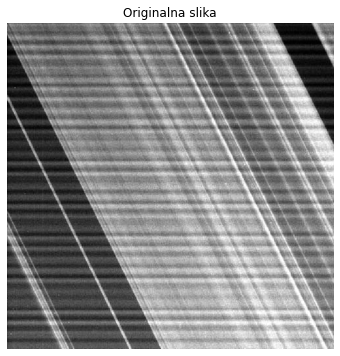

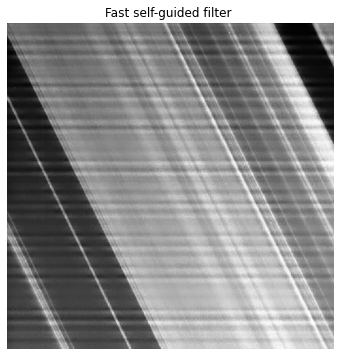

In [20]:
img9 = ski.img_as_float(ski.io.imread(data_dir + 'cassini.tif'))
plt.figure(figsize=(6,6))
plt.imshow(img9, cmap='gray')   
plt.title('Originalna slika')
plt.axis('off')
plt.show()


img9 = ski.img_as_float(ski.io.imread(data_dir + 'cassini.tif'))
q = dos_fast_self_guided_filter(img9, R = 15, epsilon = 1e-2, S = 8)
plt.figure(figsize=(6,6))
plt.imshow(q, cmap='gray')   
plt.title('Fast self-guided filter ')
plt.axis('off')
plt.show()

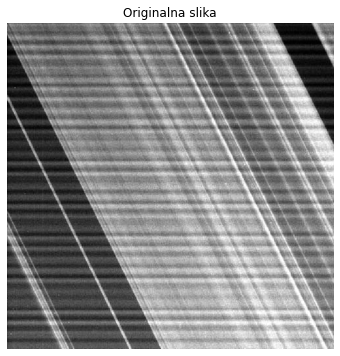

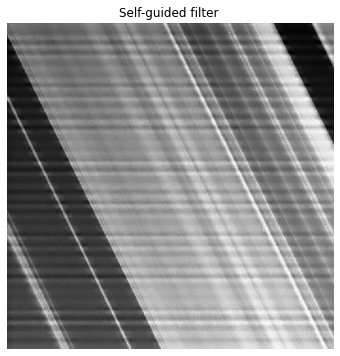

In [21]:
plt.figure(figsize=(6,6))
plt.imshow(img9, cmap='gray')   
plt.title('Originalna slika')
plt.axis('off')
plt.show()


img6 = ski.img_as_float(ski.io.imread(data_dir + 'lena.tif'))
q = dos_self_guided_filter(img9, 10, 1e-2)
plt.figure(figsize=(6,6))
plt.imshow(q, cmap='gray')   
plt.title('Self-guided filter ')
plt.axis('off')
plt.show()